# 01 — Exploratory Data Analysis

## Fraud Detection using Graphs

**Dataset:** IBM Transactions for Anti-Money Laundering (HI-Small)

### Objectives
- Understand the dataset structure
- Explore transaction features
- Analyze class imbalance
- Identify missing values
- Prepare for traditional ML and graph-based ML

## Exploratory Data Analysis — Initial Findings

### Dataset Overview
- **Dataset:** IBM Transactions for Anti-Money Laundering (HI-Small).
- **Total transactions:** 5,078,345.
- **Normal transactions:** 5,073,168.
- **Money laundering transactions:** 5,177 (approximately 0.102%).
- **Time period:** September 1–18, 2022.
- **Unique bank IDs:** 30,470.
- **Missing values:** No missing values were detected.

### Class Imbalance
- The dataset is highly imbalanced, with approximately 99.898% normal transactions.
- Accuracy alone is not a suitable evaluation metric because a model could achieve very high accuracy by predicting only normal transactions.
- **Precision, Recall, F1-Score, and PR-AUC** will be used to evaluate model performance.

### Payment Format Analysis
- **Cheque** is the most common payment format, followed by Credit Card and ACH.
- **ACH accounts for 4,483 of the 5,177 laundering transactions (86.6%).**
- ACH has the highest observed laundering rate (approximately 0.746%).
- No laundering transactions were observed for Reinvestment or Wire.
- Payment Format may be an important predictive feature.

### Transaction Amount Analysis
- Laundering transactions generally have higher transaction amounts than normal transactions.
- **Median Amount Paid:**
  - Normal transactions: 1,410.99
  - Laundering transactions: 8,667.21
- The median amount for laundering transactions is approximately **6.1 times higher**.
- Transaction amounts are strongly right-skewed, with extreme outliers influencing the mean.
- A logarithmic transformation may help visualize and model transaction amounts.
- Amounts are recorded in different currencies, so direct comparisons require caution.

### Graph-Based Analysis — Next Steps
- Represent bank accounts as **nodes** and transactions as **directed edges**.
- Investigate graph features such as node degree, transaction frequency, and account connectivity.
- Compare traditional XGBoost using transaction-level features with XGBoost enhanced by graph-derived features.
- Use a chronological train/validation/test split to reduce temporal data leakage.

In [22]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
DATA_PATH = Path("../data/HI-Small_Trans.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5078345, 11)


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5078345 entries, 0 to 5078344
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Timestamp           str    
 1   From Bank           int64  
 2   Account             str    
 3   To Bank             int64  
 4   Account.1           str    
 5   Amount Received     float64
 6   Receiving Currency  str    
 7   Amount Paid         float64
 8   Payment Currency    str    
 9   Payment Format      str    
 10  Is Laundering       int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 699.6 MB


In [25]:
df.isna().sum()

Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64

In [26]:
df["Is Laundering"].value_counts()

Is Laundering
0    5073168
1       5177
Name: count, dtype: int64

In [27]:
df = df.rename(columns={
    "Account": "From Account",
    "Account.1": "To Account"
})

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

df.head()

,Timestamp,From Bank,From Account,To Bank,To Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [28]:
print("First transaction:", df["Timestamp"].min())
print("Last transaction:", df["Timestamp"].max())

print("Number of banks:", pd.concat([
    df["From Bank"],
    df["To Bank"]
]).nunique())

First transaction: 2022-09-01 00:00:00
Last transaction: 2022-09-18 16:18:00
Number of banks: 30470


In [29]:
df = df.rename(columns={
    "Account": "From Account",
    "Account.1": "To Account"
})

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

df.head()

,Timestamp,From Bank,From Account,To Bank,To Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


In [30]:
print("First transaction:", df["Timestamp"].min())
print("Last transaction:", df["Timestamp"].max())

print("Number of banks:", pd.concat([
    df["From Bank"],
    df["To Bank"]
]).nunique())

First transaction: 2022-09-01 00:00:00
Last transaction: 2022-09-18 16:18:00
Number of banks: 30470


In [31]:
df["Payment Format"].value_counts()

Payment Format
Cheque          1864331
Credit Card     1323324
ACH              600797
Cash             490891
Reinvestment     481056
Wire             171855
Bitcoin          146091
Name: count, dtype: int64

In [32]:
pd.crosstab(
    df["Payment Format"],
    df["Is Laundering"]
)

Is Laundering,0,1
Payment Format,,
ACH,596314,4483
Bitcoin,146035,56
Cash,490783,108
Cheque,1864007,324
Credit Card,1323118,206
Reinvestment,481056,0
Wire,171855,0


In [33]:
payment_stats = pd.crosstab(
    df["Payment Format"],
    df["Is Laundering"]
)

payment_stats["Total"] = payment_stats[0] + payment_stats[1]

payment_stats["Laundering Rate (%)"] = (
    payment_stats[1] / payment_stats["Total"] * 100
)

payment_stats.sort_values(
    "Laundering Rate (%)",
    ascending=False
)

Is Laundering,0,1,Total,Laundering Rate (%)
Payment Format,,,,
ACH,596314,4483,600797,0.746175
Bitcoin,146035,56,146091,0.038332
Cash,490783,108,490891,0.022001
Cheque,1864007,324,1864331,0.017379
Credit Card,1323118,206,1323324,0.015567
Reinvestment,481056,0,481056,0.000000
Wire,171855,0,171855,0.000000


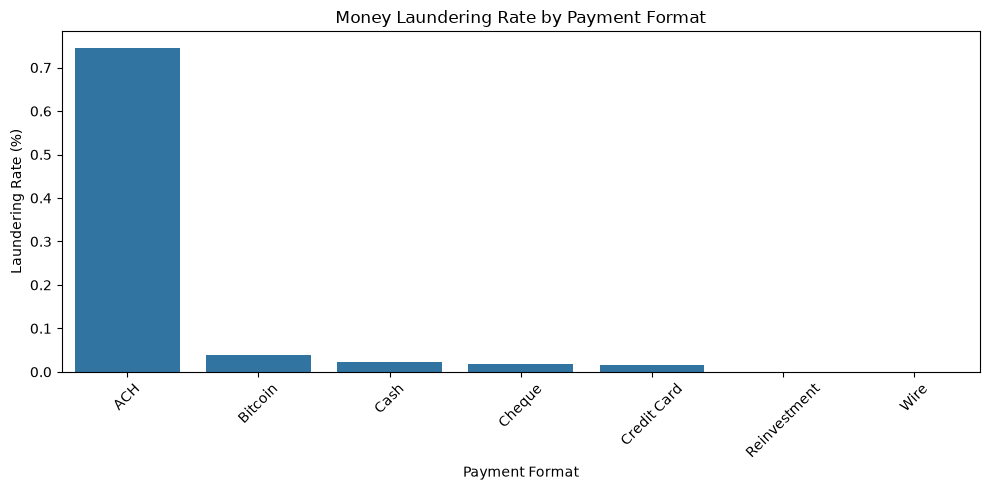

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_stats.reset_index(),
    x="Payment Format",
    y="Laundering Rate (%)"
)

plt.title("Money Laundering Rate by Payment Format")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
df.groupby("Is Laundering")["Amount Paid"].describe()

,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,5073168.0,4.477000e+06,8.688463e+08,0.000001,184.16,1410.99,12279.34,1.046302e+12
1,5177.0,3.613531e+07,1.527919e+09,0.003227,2634.97,8667.21,18832.27,8.485314e+10


In [36]:
df.groupby("Is Laundering")["Amount Received"].describe()

,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,5073168.0,5.957962e+06,1.036563e+09,0.000001,183.07,1407.51,12322.51,1.046302e+12
1,5177.0,3.613531e+07,1.527919e+09,0.003227,2634.97,8667.21,18832.27,8.485314e+10


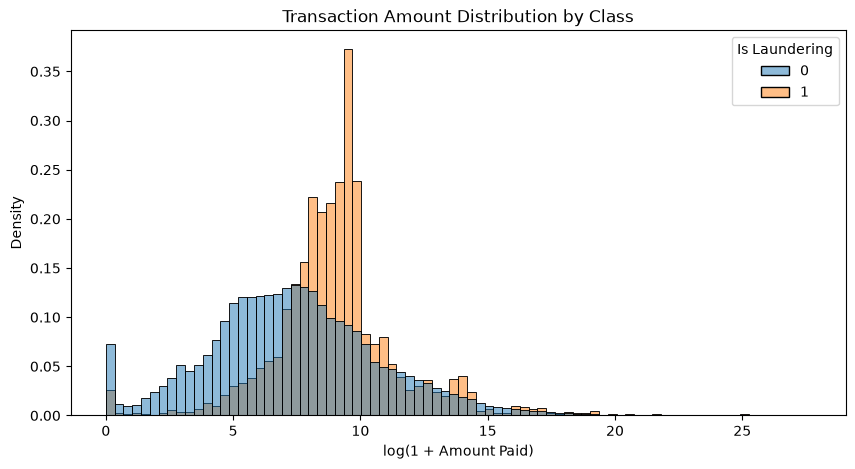

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=np.log1p(df["Amount Paid"]),
    hue="Is Laundering",
    bins=80,
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("log(1 + Amount Paid)")
plt.show()

In [38]:
df["Amounts Equal"] = np.isclose(
    df["Amount Paid"],
    df["Amount Received"]
)

pd.crosstab(
    df["Is Laundering"],
    df["Amounts Equal"],
    normalize="index"
)

Amounts Equal,False,True
Is Laundering,,
0,0.014223,0.985777
1,0.000000,1.000000


In [39]:
df["Payment Currency"].value_counts()

Payment Currency
US Dollar            1895172
Euro                 1168297
Swiss Franc           234860
Yuan                  213752
Shekel                192184
Rupee                 190202
UK Pound              180738
Yen                   155209
Ruble                 155178
Bitcoin               146066
Canadian Dollar       140042
Australian Dollar     136769
Mexican Peso          110159
Saudi Riyal            89014
Brazil Real            70703
Name: count, dtype: int64

In [40]:
pd.crosstab(
    df["Payment Currency"],
    df["Is Laundering"]
)

Is Laundering,0,1
Payment Currency,,
Australian Dollar,136642,127
Bitcoin,146010,56
Brazil Real,70646,57
Canadian Dollar,139914,128
Euro,1166925,1372
Mexican Peso,110067,92
Ruble,155045,133
Rupee,190035,167
Saudi Riyal,88640,374
